# RQ01 a RQ04: estatística descritiva das métricas DORA (Issue #64)

Lê só `lab03/code/data/dataset_dora.csv` (gerado por `python gerar_dataset.py --config config.yaml`)
e responde às RQ01 a RQ04 com **mediana, Q1, Q3 e IQR** de cada métrica em todas as variantes.
As distribuições são muito assimétricas, então a média e o desvio-padrão não são usados como medida principal.

Saídas: `tabelas/rq01_04_descritiva.csv` e as figuras `figuras/rq0*.png`.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ANALISE = Path.cwd()
CODE = ANALISE.parent / "code"
sys.path.insert(0, str(CODE))
from metrics.classificacao import (
    UM_POR_MES_EM_SEMANAS, classificar_cfr, classificar_lead_time,
)

FIGURAS = ANALISE / "figuras"
TABELAS = ANALISE / "tabelas"
FIGURAS.mkdir(exist_ok=True)
TABELAS.mkdir(exist_ok=True)

df = pd.read_csv(CODE / "data" / "dataset_dora.csv")
print(f"{len(df)} repositórios, {len(df.columns)} colunas")

300 repositórios, 42 colunas


In [2]:
# Estilo das figuras: marcas finas, grade discreta, texto em cinza-escuro
AZUL, LARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
TEXTO, TEXTO_2, GRADE = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.edgecolor": TEXTO_2, "axes.labelcolor": TEXTO, "text.color": TEXTO,
    "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "figure.constrained_layout.use": True,
    "figure.constrained_layout.wspace": 0.12,
})


def caixas(ax, series, cores, rotulos, log=False):
    """Boxplot com os pontos de cada repositório por cima (jitter horizontal)."""
    dados = [s.dropna().to_numpy() for s in series]
    if log:
        dados = [d[d > 0] for d in dados]
    bp = ax.boxplot(dados, widths=0.5, showfliers=False, patch_artist=True,
                    medianprops=dict(color=TEXTO, linewidth=1.6))
    rng = np.random.default_rng(42)
    for i, (d, cor) in enumerate(zip(dados, cores), start=1):
        bp["boxes"][i - 1].set(facecolor=cor + "33", edgecolor=cor, linewidth=1.2)
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(d)), d, s=9, color=cor,
                   alpha=0.55, linewidths=0, zorder=3)
    ax.set_xticks(range(1, len(rotulos) + 1), rotulos)
    if log:
        ax.set_yscale("log")


def limites(ax, valores, nomes, eixo="y"):
    """Linhas tracejadas nos cortes da tabela DORA da disciplina."""
    for v, nome in zip(valores, nomes):
        (ax.axhline if eixo == "y" else ax.axvline)(v, color=TEXTO_2, linestyle="--", linewidth=0.8)
        if eixo == "y":
            ax.annotate(nome, (1, v), xycoords=("axes fraction", "data"), xytext=(3, 0),
                        textcoords="offset points", va="center", fontsize=7.5, color=TEXTO_2)

## Tabela única: mediana e IQR de todas as métricas e variantes

Unidades: frequência em *deploys* por semana, *lead time* em dias, CFR em %, tempo de recuperação em horas.
`n` é o número de repositórios com a métrica definida (por exemplo, o CFR (b) fica indefinido quando todas as
*releases* do repositório são censuradas, e o tempo de recuperação quando não há nenhum episódio recuperado).

In [3]:
VARIANTES = [
    # (RQ, métrica, variante, coluna, unidade, fator de conversão)
    ("RQ01", "Deployment frequency", "release (principal)", "deploy_freq_release", "deploys/semana", 1),
    ("RQ01", "Deployment frequency", "release + pré-release", "deploy_freq_release_pre", "deploys/semana", 1),
    ("RQ01", "Deployment frequency", "tag", "deploy_freq_tag", "deploys/semana", 1),
    ("RQ02", "Lead time", "(a) por release", "lead_time_a_horas", "dias", 1 / 24),
    ("RQ02", "Lead time", "(b) por commit", "lead_time_b_horas", "dias", 1 / 24),
    ("RQ03", "Change failure rate", "(a) proxy de CI", "cfr_a", "%", 100),
    ("RQ03", "Change failure rate", "(b) proxy de entrega", "cfr_b", "%", 100),
    ("RQ04", "Tempo de recuperação", "episódio de falha de CI", "tempo_recuperacao_horas", "horas", 1),
]


def resumo(serie):
    s = serie.dropna()
    q1, med, q3 = s.quantile([0.25, 0.5, 0.75])
    return {"n": len(s), "mediana": med, "Q1": q1, "Q3": q3, "IQR": q3 - q1, "mín": s.min(), "máx": s.max()}


tabela = pd.DataFrame([
    {"RQ": rq, "métrica": m, "variante": v, "unidade": u, **resumo(df[col] * fator)}
    for rq, m, v, col, u, fator in VARIANTES
])
tabela.to_csv(TABELAS / "rq01_04_descritiva.csv", index=False)
tabela.round(2)

,RQ,métrica,variante,unidade,n,mediana,Q1,Q3,IQR,mín,máx
0,RQ01,Deployment frequency,release (principal),deploys/semana,300,0.35,0.17,0.77,0.59,0.02,73.26
1,RQ01,Deployment frequency,release + pré-release,deploys/semana,300,0.38,0.19,0.88,0.69,0.02,73.32
2,RQ01,Deployment frequency,tag,deploys/semana,300,0.45,0.23,1.02,0.79,0.02,135.13
3,RQ02,Lead time,(a) por release,dias,299,10.56,2.16,33.28,31.12,0.00,3463.36
4,RQ02,Lead time,(b) por commit,dias,299,8.12,2.04,29.56,27.53,-12.86,2871.23
5,RQ03,Change failure rate,(a) proxy de CI,%,300,5.73,2.00,13.46,11.46,0.00,86.09
6,RQ03,Change failure rate,(b) proxy de entrega,%,300,12.50,0.00,30.19,30.19,0.00,100.00
7,RQ04,Tempo de recuperação,episódio de falha de CI,horas,276,3.13,0.91,17.42,16.51,0.03,1650.14


## RQ01. Frequência de *deploy*

*Releases* publicadas na janela ÷ 52,1 semanas. As variantes com pré-*releases* e com *tags* são as da RQ07.
As linhas tracejadas marcam os cortes da tabela DORA (≥ 7/semana Elite, ≥ 1/semana High, ≥ 1/mês Medium).

Repositórios por faixa (release):
deploy_freq_release
< 1/mês             98
1/mês a < 1/sem    149
1 a < 7/sem         50
≥ 7/sem              3

Tags com frequência zero na janela: 0 repositórios (fora do gráfico em log)


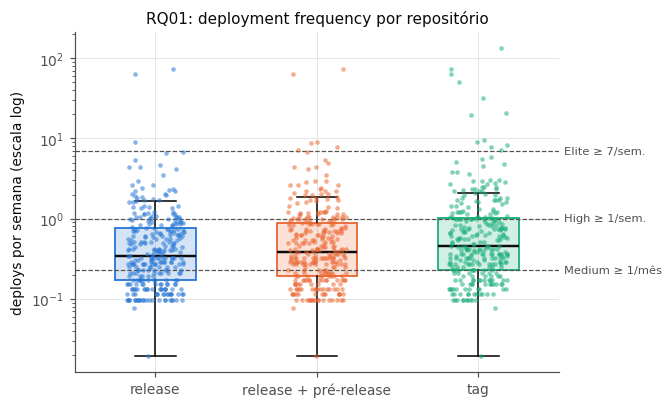

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.6))
caixas(ax, [df.deploy_freq_release, df.deploy_freq_release_pre, df.deploy_freq_tag],
       [AZUL, LARANJA, AQUA], ["release", "release + pré-release", "tag"], log=True)
limites(ax, [7, 1, UM_POR_MES_EM_SEMANAS], ["Elite ≥ 7/sem.", "High ≥ 1/sem.", "Medium ≥ 1/mês"])
ax.set_ylabel("deploys por semana (escala log)")
ax.set_title("RQ01: deployment frequency por repositório")
fig.savefig(FIGURAS / "rq01_deploy_frequency.png")

df_rel = df.deploy_freq_release
print("Repositórios por faixa (release):")
print(pd.cut(df_rel, [0, UM_POR_MES_EM_SEMANAS, 1, 7, np.inf], right=False,
             labels=["< 1/mês", "1/mês a < 1/sem", "1 a < 7/sem", "≥ 7/sem"]).value_counts().sort_index().to_string())
print(f"\nTags com frequência zero na janela: {(df.deploy_freq_tag == 0).sum()} repositórios (fora do gráfico em log)")

## RQ02. *Lead time* (a) por *release* × (b) por *commit*

Por construção, o *lead time* (a) de uma *release* é o maior entre os *lead times* (b) dos seus *commits*
(é o do *commit* mais antigo). A variante (a) é a mediana desses máximos, e a (b), a mediana de todos os
*commits* juntos; por isso (a) tende a ficar acima de (b), e a distância entre as duas mede o quanto as
*releases* carregam *commits* antigos.

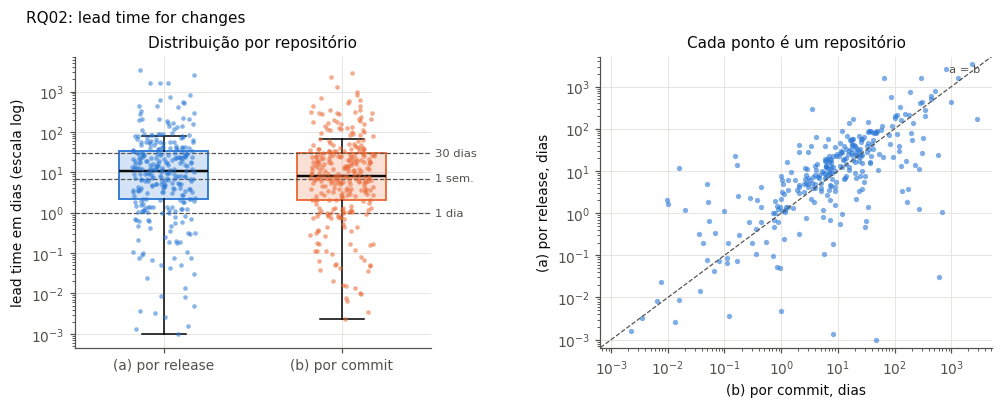

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.6), gridspec_kw={"width_ratios": [1, 1.1]})
caixas(ax1, [df.lead_time_a_horas / 24, df.lead_time_b_horas / 24], [AZUL, LARANJA],
       ["(a) por release", "(b) por commit"], log=True)
limites(ax1, [1, 7, 30], ["1 dia", "1 sem.", "30 dias"])
ax1.set_ylabel("lead time em dias (escala log)")
ax1.set_title("Distribuição por repositório")

lt = df.dropna(subset=["lead_time_a_horas", "lead_time_b_horas"])
lt = lt[(lt.lead_time_a_horas > 0) & (lt.lead_time_b_horas > 0)]
x, y = lt.lead_time_b_horas / 24, lt.lead_time_a_horas / 24
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.scatter(x, y, s=12, color=AZUL, alpha=0.6, linewidths=0)
lim = [min(x.min(), y.min()) / 1.5, max(x.max(), y.max()) * 1.5]
ax2.plot(lim, lim, color=TEXTO_2, linestyle="--", linewidth=0.8)
ax2.set_xlim(lim); ax2.set_ylim(lim)
ax2.annotate("a = b", (lim[1], lim[1]), xytext=(-28, -10), textcoords="offset points", fontsize=7.5, color=TEXTO_2)
ax2.set_xlabel("(b) por commit, dias"); ax2.set_ylabel("(a) por release, dias")
ax2.set_title("Cada ponto é um repositório")
fig.suptitle("RQ02: lead time for changes", x=0.02, ha="left", fontsize=10)
fig.savefig(FIGURAS / "rq02_lead_time.png")

In [6]:
ambos = df.dropna(subset=["lead_time_a_horas", "lead_time_b_horas"])
razao = ambos.lead_time_a_horas / ambos.lead_time_b_horas
rho, p_rho = stats.spearmanr(ambos.lead_time_a_horas, ambos.lead_time_b_horas)
w = stats.wilcoxon(ambos.lead_time_a_horas, ambos.lead_time_b_horas)
print(f"n = {len(ambos)} repositórios com as duas variantes")
print(f"(a) > (b) em {(razao > 1).mean():.1%} dos repositórios; (a) ≥ 2×(b) em {(razao >= 2).mean():.1%}")
print(f"razão (a)/(b): mediana {razao.median():.2f} (Q1 {razao.quantile(.25):.2f}, Q3 {razao.quantile(.75):.2f})")
print(f"Spearman entre as variantes: ρ = {rho:.3f} (p = {p_rho:.2g})")
print(f"Wilcoxon pareado (a) × (b): W = {w.statistic:.0f}, p = {w.pvalue:.2g}")

ordem = ["Elite", "High", "Medium", "Low"]
cat_a = ambos.lead_time_a_horas.map(classificar_lead_time)
cat_b = ambos.lead_time_b_horas.map(classificar_lead_time)
print(f"\nMesma categoria DORA nas duas variantes: {(cat_a == cat_b).mean():.1%}")
pd.crosstab(pd.Categorical(cat_a, ordem), pd.Categorical(cat_b, ordem),
            rownames=["(a) por release"], colnames=["(b) por commit"], dropna=False)

n = 299 repositórios com as duas variantes
(a) > (b) em 62.9% dos repositórios; (a) ≥ 2×(b) em 33.1%
razão (a)/(b): mediana 1.41 (Q1 0.59, Q3 2.47)
Spearman entre as variantes: ρ = 0.716 (p = 3.4e-48)
Wilcoxon pareado (a) × (b): W = 16168, p = 2.9e-05

Mesma categoria DORA nas duas variantes: 55.2%


(b) por commit,Elite,High,Medium,Low
(a) por release,,,,
Elite,33,6,5,4
High,17,39,15,6
Medium,4,29,44,16
Low,0,6,26,49


In [7]:
excluidas = df[["lt_releases_sem_anterior", "lt_releases_404", "lt_releases_indisponivel", "lt_releases_sem_commits"]].sum()
print(f"Releases na janela: {int(df.n_releases.sum())}; avaliadas no lead time: {int(df.lt_releases_avaliadas.sum())} "
      f"({int(df.lt_commits_avaliados.sum())} commits)")
print("Fora do lead time:")
print(excluidas.astype(int).rename({"lt_releases_sem_anterior": "primeira release da história",
                        "lt_releases_404": "compare com 404 (tag apagada)",
                        "lt_releases_indisponivel": "compare indisponível (grande demais)",
                        "lt_releases_sem_commits": "sem commits novos"}).to_string())

Releases na janela: 17859; avaliadas no lead time: 13531 (1361066 commits)
Fora do lead time:
primeira release da história              56
compare com 404 (tag apagada)              0
compare indisponível (grande demais)       0
sem commits novos                       4272


## RQ03. *Change failure rate* (a) proxy de CI × (b) proxy de entrega

(a) = execuções com falha ÷ (falhas + sucessos). (b) = *releases* seguidas em até 7 dias por uma *release*
corretiva (heurística v3) ÷ *releases* avaliadas. Linhas nos cortes de 15%, 30% e 45%.

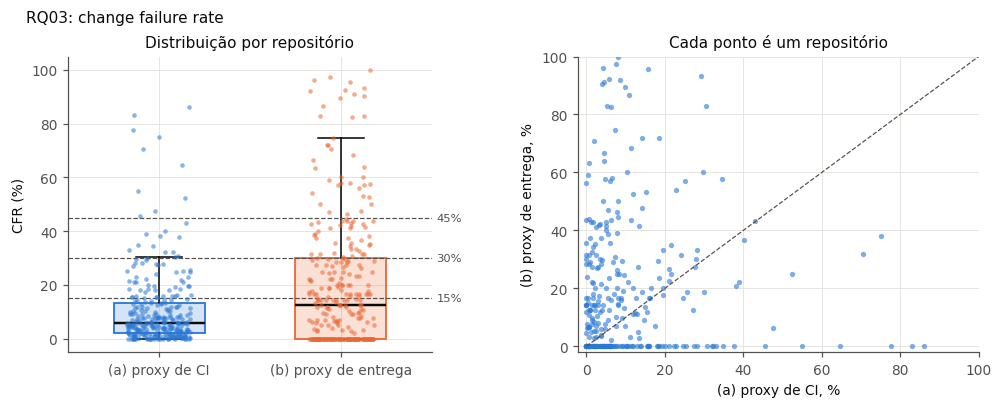

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.6), gridspec_kw={"width_ratios": [1, 1.1]})
caixas(ax1, [df.cfr_a * 100, df.cfr_b * 100], [AZUL, LARANJA], ["(a) proxy de CI", "(b) proxy de entrega"])
limites(ax1, [15, 30, 45], ["15%", "30%", "45%"])
ax1.set_ylabel("CFR (%)")
ax1.set_title("Distribuição por repositório")

cfr = df.dropna(subset=["cfr_a", "cfr_b"])
ax2.scatter(cfr.cfr_a * 100, cfr.cfr_b * 100, s=12, color=AZUL, alpha=0.6, linewidths=0)
topo = min(100, max(cfr.cfr_a.max(), cfr.cfr_b.max()) * 100 * 1.1)
ax2.plot([0, topo], [0, topo], color=TEXTO_2, linestyle="--", linewidth=0.8)
ax2.set_xlim(-topo * 0.02, topo); ax2.set_ylim(-topo * 0.02, topo)
ax2.set_xlabel("(a) proxy de CI, %"); ax2.set_ylabel("(b) proxy de entrega, %")
ax2.set_title("Cada ponto é um repositório")
fig.suptitle("RQ03: change failure rate", x=0.02, ha="left", fontsize=10)
fig.savefig(FIGURAS / "rq03_cfr.png")

In [9]:
rho, p_rho = stats.spearmanr(cfr.cfr_a, cfr.cfr_b)
w = stats.wilcoxon(cfr.cfr_a, cfr.cfr_b)
print(f"n = {len(cfr)} repositórios com as duas variantes")
print(f"(a) > (b) em {(cfr.cfr_a > cfr.cfr_b).mean():.1%}; (b) = 0 em {(cfr.cfr_b == 0).mean():.1%}; (a) = 0 em {(cfr.cfr_a == 0).mean():.1%}")
print(f"Spearman entre as variantes: ρ = {rho:.3f} (p = {p_rho:.2g})")
print(f"Wilcoxon pareado (a) × (b): W = {w.statistic:.0f}, p = {w.pvalue:.2g}")
print(f"Releases corretivas (heurística v3): {int(df.releases_corretivas.sum())} de {int(df.n_releases.sum())} "
      f"({df.releases_corretivas.sum() / df.n_releases.sum():.1%})")

cat_a = cfr.cfr_a.map(classificar_cfr)
cat_b = cfr.cfr_b.map(classificar_cfr)
print(f"\nMesma categoria DORA nas duas variantes: {(cat_a == cat_b).mean():.1%}")
pd.crosstab(pd.Categorical(cat_a, ordem), pd.Categorical(cat_b, ordem),
            rownames=["(a) proxy de CI"], colnames=["(b) proxy de entrega"], dropna=False)

n = 300 repositórios com as duas variantes
(a) > (b) em 40.7%; (b) = 0 em 34.3%; (a) = 0 em 6.7%
Spearman entre as variantes: ρ = 0.063 (p = 0.27)
Wilcoxon pareado (a) × (b): W = 13638, p = 8e-08
Releases corretivas (heurística v3): 4509 de 17859 (25.2%)

Mesma categoria DORA nas duas variantes: 49.7%


(b) proxy de entrega,Elite,High,Medium,Low
(a) proxy de CI,,,,
Elite,133,40,29,30
High,20,14,4,7
Medium,6,3,2,2
Low,7,1,2,0


## RQ04. Tempo de recuperação

Mediana, por repositório, da duração dos episódios de falha de cada *workflow* (da primeira falha ao fim do
próximo sucesso). Linhas em 1 hora, 1 dia e 1 semana.

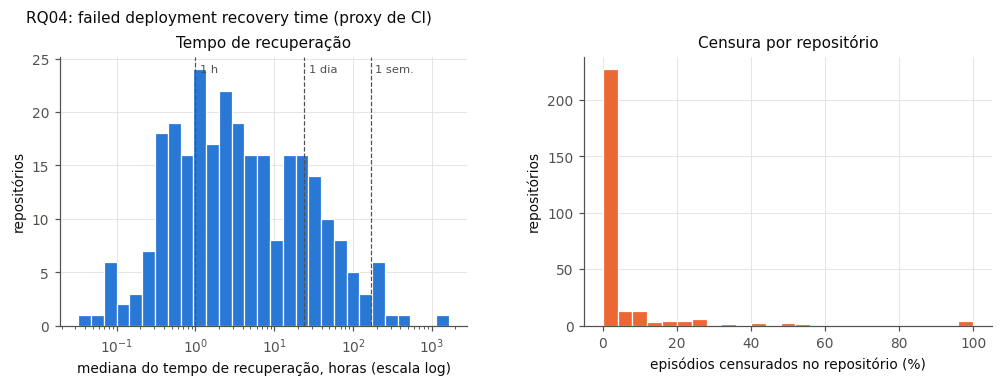

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.4))
rec = df.tempo_recuperacao_horas.dropna()
bins = np.logspace(np.log10(max(rec.min(), 0.01)), np.log10(rec.max()), 30)
ax1.hist(rec, bins=bins, color=AZUL, edgecolor="white", linewidth=0.8)
ax1.set_xscale("log")
for v, nome in [(1, "1 h"), (24, "1 dia"), (168, "1 sem.")]:
    ax1.axvline(v, color=TEXTO_2, linestyle="--", linewidth=0.8)
    ax1.annotate(nome, (v, 1), xycoords=("data", "axes fraction"), xytext=(3, -10),
                 textcoords="offset points", fontsize=7.5, color=TEXTO_2)
ax1.set_xlabel("mediana do tempo de recuperação, horas (escala log)")
ax1.set_ylabel("repositórios")
ax1.set_title("Tempo de recuperação")

prop = df.prop_episodios_censurados.dropna() * 100
ax2.hist(prop, bins=np.arange(0, 102, 4), color=LARANJA, edgecolor="white", linewidth=0.8)
ax2.set_xlabel("episódios censurados no repositório (%)")
ax2.set_ylabel("repositórios")
ax2.set_title("Censura por repositório")
fig.suptitle("RQ04: failed deployment recovery time (proxy de CI)", x=0.02, ha="left", fontsize=10)
fig.savefig(FIGURAS / "rq04_recuperacao.png")

## Censura

Casos censurados não são descartados: são contados e reportados. Na RQ04, um episódio é censurado quando o
*workflow* não volta a ter sucesso até o fim da janela. No CFR (b), as *releases* dos últimos 7 dias da janela
(`published_at ≥ 23/09/2026`) saem do denominador.

In [11]:
ep = df[["episodios_falha", "episodios_recuperados", "episodios_censurados"]].sum().astype(int)
print(f"RQ04: {ep.episodios_falha} episódios de falha, {ep.episodios_censurados} censurados "
      f"({ep.episodios_censurados / ep.episodios_falha:.1%} do total)")
com_ep = df[df.episodios_falha > 0]
print(f"  repositórios com algum episódio: {len(com_ep)}; com pelo menos um censurado: "
      f"{(com_ep.episodios_censurados > 0).sum()} ({(com_ep.episodios_censurados > 0).mean():.1%})")
p = com_ep.prop_episodios_censurados * 100
print(f"  % censurados por repositório: mediana {p.median():.1f}% (Q1 {p.quantile(.25):.1f}%, Q3 {p.quantile(.75):.1f}%), "
      f"máximo {p.max():.1f}%")
print(f"  repositórios sem nenhum episódio recuperado (tempo indefinido): {df.tempo_recuperacao_horas.isna().sum()}")

aval, cens = int(df.cfr_b_avaliadas.sum()), int(df.cfr_b_censuradas.sum())
print(f"\nCFR (b): {aval + cens} releases na janela, {cens} censuradas ({cens / (aval + cens):.1%}), {aval} avaliadas")
print(f"  repositórios com alguma release censurada: {(df.cfr_b_censuradas > 0).sum()}; "
      f"com CFR (b) indefinido: {df.cfr_b.isna().sum()}")

RQ04: 13926 episódios de falha, 204 censurados (1.5% do total)
  repositórios com algum episódio: 280; com pelo menos um censurado: 96 (34.3%)
  % censurados por repositório: mediana 0.0% (Q1 0.0%, Q3 2.3%), máximo 100.0%
  repositórios sem nenhum episódio recuperado (tempo indefinido): 24

CFR (b): 17859 releases na janela, 400 censuradas (2.2%), 17459 avaliadas
  repositórios com alguma release censurada: 96; com CFR (b) indefinido: 0
